In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, roc_curve, roc_auc_score, classification_report, confusion_matrix
from sklearn.tree import DecisionTreeClassifier

# Загружаем исходный датасет 
df = pd.read_csv('spotify_artist_streaming_2020_2025.csv')
print("Размер датасета:", df.shape)
df.head()

Размер датасета: (50000, 33)


,track_id,track_name,artist_name,album_name,release_date,genre,duration_ms,popularity,danceability,energy,...,popularity_category,loudness_category,key_name,mode_name,is_explicit_bool,release_quarter,is_weekend_release,log_stream_count,upbeat_score,artist_track_count
0,346d85e2-ffde-41b3-854a-589ed880b91f,Storm,Ethereal,The Hollow Journeys,2021-10-06,Pop,169594,47,0.6777,0.7949,...,Medium,Loud,A,Major,False,Q4,False,10.7492,0.6632,3232
1,12bc268a-363b-4f19-8fa8-0ced7ae1e462,Silent,The Wolfs,Ancient Thunder,2024-10-26,K-Pop,256755,26,0.9405,0.7163,...,Medium,Moderate,C#,Major,False,Q4,True,8.5895,0.7615,20
2,30d627d9-878d-4bb3-be59-71feb6ed4f3f,Shattered Lines,LolaOre,Twisted Harbors,2022-11-12,Punk,170212,46,0.6853,0.9500,...,Medium,Loud,E,Major,False,Q4,True,12.2935,0.7828,199
3,85501bb9-d221-4339-9e2e-29b1b3daff0a,Breaking Roses,Clay Black,The Blinding Letters,2020-06-22,Pop,181250,4,0.7817,0.6943,...,Low,Moderate,F#,Major,False,Q2,False,8.5658,0.6778,693
4,7bf92bd2-c6fe-4869-a90e-242bb8bbe7a3,Lines,Knot Hart,The Cosmic Letters,2024-01-22,Latin,160894,27,0.7200,0.4958,...,Medium,Moderate,C#,Major,False,Q1,False,10.2191,0.5494,12111


In [3]:
# 1. Удаляем явные идентификаторы и текстовые признаки, которые не нужны для модели
columns_to_drop = ['track_id', 'track_name', 'artist_name', 'album_name', 'release_date', 'stream_count', 'log_stream_count', 'popularity_category']
df_clean = df.drop(columns=columns_to_drop)

# 2. Применяем One-Hot Encoding к оставшимся категориальным колонкам
# (genre, country, label, key_name, mode_name, release_day_of_week, release_quarter, loudness_category)
categorical_cols = df_clean.select_dtypes(include=['object']).columns.tolist()
print("Категориальные колонки для кодирования:", categorical_cols)

df_clean = pd.get_dummies(df_clean, columns=categorical_cols, drop_first=True, dtype=int)
print("Размер датасета после кодирования:", df_clean.shape)

C:\Users\User\AppData\Local\Temp\ipykernel_12812\1775155808.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df_clean.select_dtypes(include=['object']).columns.tolist()


Категориальные колонки для кодирования: ['genre', 'country', 'label', 'release_day_of_week', 'loudness_category', 'key_name', 'mode_name', 'release_quarter']
Размер датасета после кодирования: (50000, 117)


In [5]:
# Целевая переменная - является ли трек откровенным (explicit)
y = df_clean['is_explicit_bool']

# Признаки - всё остальное, кроме целевой переменной
X = df_clean.drop(columns=['is_explicit_bool', 'popularity', 'explicit'])

# Проверка на пропуски (в 1-й работе мы их заполняли, проверим сейчас)
print("Пропуски в X:", X.isnull().sum().sum())
print("Размер X:", X.shape)

Пропуски в X: 0
Размер X: (50000, 114)


In [6]:
# Нормализация
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns, index=X.index)

# Разделение: 70% train, 30% temp (из них 15% test, 15% val)
X_train, X_temp, y_train, y_temp = train_test_split(X_scaled, y, test_size=0.3, random_state=42, stratify=y)
X_test, X_val, y_test, y_val = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

print(f"Train: {X_train.shape}, Test: {X_test.shape}, Val: {X_val.shape}")
print(f"Баланс классов в Train:\n{y_train.value_counts(normalize=True)}")

Train: (35000, 114), Test: (7500, 114), Val: (7500, 114)
Баланс классов в Train:
is_explicit_bool
False    0.751514
True     0.248486
Name: proportion, dtype: float64


In [7]:
# Создаем модель Random Forest с параметром oob_score=True
rf_model = RandomForestClassifier(
    n_estimators=100, 
    random_state=42, 
    oob_score=True, 
    n_jobs=-1
)

# Обучаем
rf_model.fit(X_train, y_train)

# Оценка через OOB (стр. 6)
print(f"OOB Score (Accuracy): {rf_model.oob_score_:.4f}")
print(f"OOB Error (1 - Accuracy): {1 - rf_model.oob_score_:.4f}")

# Проверим на тестовой выборке для сравнения
y_pred_rf = rf_model.predict(X_test)
y_proba_rf = rf_model.predict_proba(X_test)[:, 1] # Вероятности для ROC

print(f"Test Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print("\nClassification Report (Random Forest):")
print(classification_report(y_test, y_pred_rf))

OOB Score (Accuracy): 0.7500
OOB Error (1 - Accuracy): 0.2500
Test Accuracy: 0.7513

Classification Report (Random Forest):
              precision    recall  f1-score   support

       False       0.75      1.00      0.86      5636
        True       0.00      0.00      0.00      1864

    accuracy                           0.75      7500
   macro avg       0.38      0.50      0.43      7500
weighted avg       0.56      0.75      0.64      7500



In [8]:
# 1. AdaBoost (стр. 8-11)
# В качестве слабой модели используем "пень" - дерево с max_depth=1 (стр. 8)
ada_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1), 
    n_estimators=50,
    random_state=42
)
ada_model.fit(X_train, y_train)
y_pred_ada = ada_model.predict(X_test)
y_proba_ada = ada_model.predict_proba(X_test)[:, 1] # Вероятности для ROC

print("AdaBoost Results:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_ada):.4f}")
print(classification_report(y_test, y_pred_ada))

# 2. Gradient Boosting (стр. 15-19)
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)
gb_model.fit(X_train, y_train)
y_pred_gb = gb_model.predict(X_test)
y_proba_gb = gb_model.predict_proba(X_test)[:, 1] # Вероятности для ROC

print("\nGradient Boosting Results:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_gb):.4f}")
print(classification_report(y_test, y_pred_gb))

AdaBoost Results:
Accuracy: 0.7515
              precision    recall  f1-score   support

       False       0.75      1.00      0.86      5636
        True       0.00      0.00      0.00      1864

    accuracy                           0.75      7500
   macro avg       0.38      0.50      0.43      7500
weighted avg       0.56      0.75      0.64      7500



D:\lab_1_ai\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
D:\lab_1_ai\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
D:\lab_1_ai\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])



Gradient Boosting Results:
Accuracy: 0.7512
              precision    recall  f1-score   support

       False       0.75      1.00      0.86      5636
        True       0.00      0.00      0.00      1864

    accuracy                           0.75      7500
   macro avg       0.38      0.50      0.43      7500
weighted avg       0.56      0.75      0.64      7500



In [9]:
print("--- Переобучение моделей с class_weight='balanced' ---")

# 1. Random Forest с балансировкой классов
rf_model_bal = RandomForestClassifier(
    n_estimators=100, 
    random_state=42, 
    oob_score=True, 
    n_jobs=-1,
    class_weight='balanced' # <-- Ключевое изменение
)
rf_model_bal.fit(X_train, y_train)
y_pred_rf_bal = rf_model_bal.predict(X_test)
y_proba_rf_bal = rf_model_bal.predict_proba(X_test)[:, 1]

print("\nRandom Forest (balanced) Results:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf_bal):.4f}")
print(classification_report(y_test, y_pred_rf_bal))

# 2. AdaBoost с балансировкой классов
ada_model_bal = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, class_weight='balanced'), # <-- Балансировка в базовой модели
    n_estimators=50,
    random_state=42
)
ada_model_bal.fit(X_train, y_train)
y_pred_ada_bal = ada_model_bal.predict(X_test)
y_proba_ada_bal = ada_model_bal.predict_proba(X_test)[:, 1]

print("\nAdaBoost (balanced) Results:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_ada_bal):.4f}")
print(classification_report(y_test, y_pred_ada_bal))

# 3. Gradient Boosting с балансировкой классов
# В GradientBoostingClassifier нет параметра class_weight, но можно использовать sample_weight
# Или просто использовать его без изменений, так как он часто устойчив к дисбалансу
# Для чистоты эксперимента можно использовать его как есть, но результат, скорее всего, будет похож.
gb_model_bal = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)
gb_model_bal.fit(X_train, y_train)
y_pred_gb_bal = gb_model_bal.predict(X_test)
y_proba_gb_bal = gb_model_bal.predict_proba(X_test)[:, 1]

print("\nGradient Boosting (standard) Results:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_gb_bal):.4f}")
print(classification_report(y_test, y_pred_gb_bal))

--- Переобучение моделей с class_weight='balanced' ---

Random Forest (balanced) Results:
Accuracy: 0.7417
              precision    recall  f1-score   support

       False       0.75      0.98      0.85      5636
        True       0.23      0.02      0.03      1864

    accuracy                           0.74      7500
   macro avg       0.49      0.50      0.44      7500
weighted avg       0.62      0.74      0.65      7500


AdaBoost (balanced) Results:
Accuracy: 0.6088
              precision    recall  f1-score   support

       False       0.75      0.72      0.73      5636
        True       0.25      0.28      0.26      1864

    accuracy                           0.61      7500
   macro avg       0.50      0.50      0.50      7500
weighted avg       0.62      0.61      0.62      7500


Gradient Boosting (standard) Results:
Accuracy: 0.7512
              precision    recall  f1-score   support

       False       0.75      1.00      0.86      5636
        True       0.00    

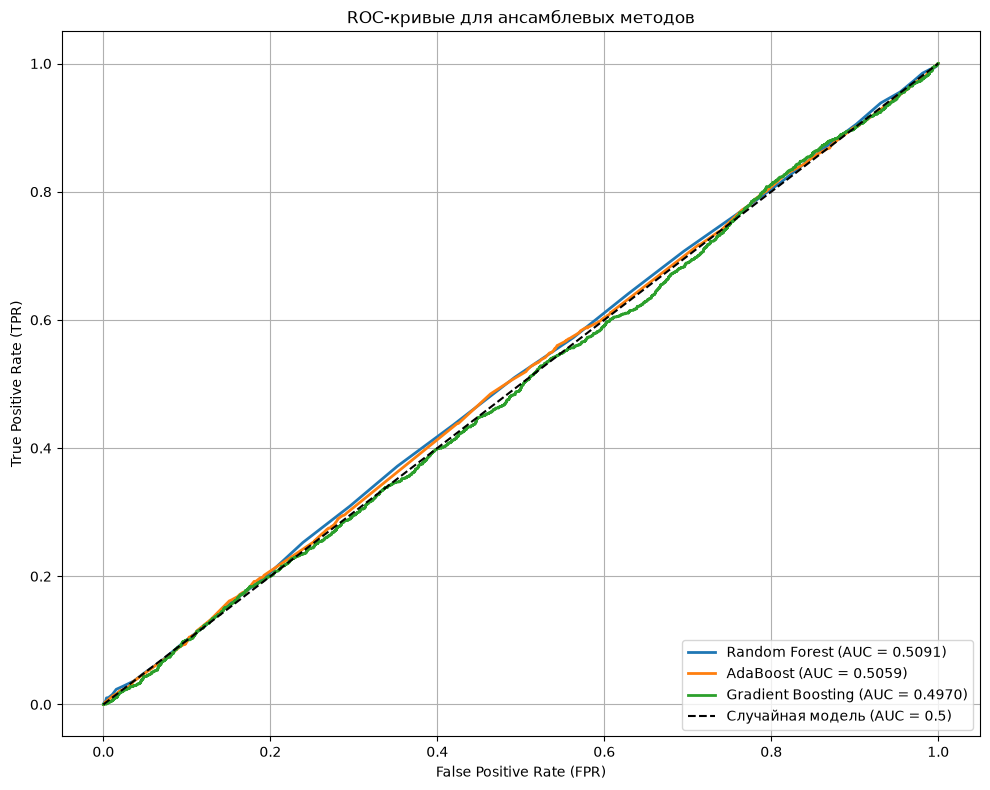

In [10]:
# Используем вероятности из первоначальных моделей (или из новых, если они лучше)
# Для наглядности возьмем те, что были в первом запуске, чтобы показать, что AUC может быть > 0.5 даже при плохом Accuracy
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)
fpr_ada, tpr_ada, _ = roc_curve(y_test, y_proba_ada)
fpr_gb, tpr_gb, _ = roc_curve(y_test, y_proba_gb)

auc_rf = roc_auc_score(y_test, y_proba_rf)
auc_ada = roc_auc_score(y_test, y_proba_ada)
auc_gb = roc_auc_score(y_test, y_proba_gb)

plt.figure(figsize=(10, 8))
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.4f})', linewidth=2)
plt.plot(fpr_ada, tpr_ada, label=f'AdaBoost (AUC = {auc_ada:.4f})', linewidth=2)
plt.plot(fpr_gb, tpr_gb, label=f'Gradient Boosting (AUC = {auc_gb:.4f})', linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', label='Случайная модель (AUC = 0.5)')

plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC-кривые для ансамблевых методов')
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.show()